# iGaming Player Churn: A CRISP-DM Walkthrough

This notebook follows the six CRISP-DM phases: **Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, and Deployment**. We use player activity data to build a churn-risk model, then explore how its scores might support a retention campaign.

## 1. Business Understanding

### The business question

Acquiring a new player can be expensive. One industry estimate put gambling marketing spend at [$3.9 billion](https://www.5wpr.com/new/the-gambling-industry-spent-3-9-billion-on-marketing-last-year-here-is-what-the-data-shows/), and [iGaming Business](https://igamingbusiness.com/marketing-affiliates/dot-player-churn-a-real-problem/) has also described churn as a persistent challenge. The practical question is: **can we spot signs of disengagement early enough to consider a helpful, responsible intervention?**

Unlike a subscription customer, a player usually does not announce that they are leaving. We define a working churn label as no cash-game, tournament, or deposit activity during the 45 days after a 30-day observation period. The clock begins with each player's first recorded activity, and only players with complete follow-up are included.

We will compare candidate models using stratified cross-validation, evaluate the selected model on a held-out test set, and pay particular attention to precision-recall performance as well as ROC-AUC. Finally, we will estimate campaign economics across thresholds using explicit assumptions for player value, offer cost, and campaign success.

These calculations can help prioritize a pilot; they cannot show that a campaign causes retention. Any real deployment should be tested carefully and include responsible-gambling safeguards.

### Project scope

The supplied data covers demographics, cash games, tournaments, deposits, and withdrawals. Cash games, tournaments, and deposits contribute to the churn label; the feature set focuses on cash-game and deposit behaviour. Withdrawals are profiled but are not model inputs in this version.


## 2. Data Understanding

Before preparing features, we take a practical look at the source files: how many records and players they contain, what dates they cover, whether transaction records connect to known player profiles, and which important fields are missing. These checks help us understand what conclusions the data can support.


In [60]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import duckdb

In [61]:
# Connecting to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

In [62]:
# Grouping the datasets into a dictionary for easy access
data = {
    'Demographics': 'datasets/SecondSeshData1Demographics.csv',
    'CashGames': 'datasets/SecondSeshData2CashGames.csv',
    'Tournaments': 'datasets/SecondSeshData3Tournaments.csv',
    'Deposits': 'datasets/SecondSeshData4Deposits.csv',
    'Withdrawals': 'datasets/SecondSeshData5Withdrawals.csv',
}

In [63]:
for table_name, file_path in data.items():
    query = f"CREATE OR REPLACE VIEW {table_name} AS SELECT * FROM read_csv_auto('{file_path}')"
    con.execute(query)

print("All CSV views registered successfully in DuckDB!")

All CSV views registered successfully in DuckDB!


In [64]:
# See all registered views
con.execute("SHOW TABLES").fetchdf()

,name
0,CashGames
1,Demographics
2,Deposits
3,Tournaments
4,Withdrawals


In [65]:
# Check shape,number of users, and min/max dates for each table
audit_query = """
SELECT 
    'Demographics' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(DISTINCT UserID) AS unique_users,
    NULL AS min_date,
    NULL AS max_date
FROM Demographics

UNION ALL

SELECT 
    'CashGames',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(Date AS TIMESTAMP)),
    MAX(CAST(Date AS TIMESTAMP))
FROM CashGames

UNION ALL

SELECT 
    'Tournaments',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(Date AS TIMESTAMP)),
    MAX(CAST(Date AS TIMESTAMP))
FROM Tournaments

UNION ALL

SELECT 
    'Deposits',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(ProcessDate AS TIMESTAMP)),
    MAX(CAST(ProcessDate AS TIMESTAMP))
FROM Deposits

UNION ALL

SELECT 
    'Withdrawals',
    COUNT(*),
    COUNT(DISTINCT UserID),
    MIN(CAST(ProcessDate AS TIMESTAMP)),
    MAX(CAST(ProcessDate AS TIMESTAMP))
FROM Withdrawals;
"""

# Run the query and fetch into a Pandas dataframe
audit_results = con.execute(audit_query).fetchdf()
audit_results

,table_name,total_rows,unique_users,min_date,max_date
0,Demographics,5028,5028,NaT,NaT
1,CashGames,51763,4232,2015-02-01,2020-07-28
2,Tournaments,82831,3448,2015-02-01,2021-01-01
3,Deposits,295088,5008,2015-02-01,2020-07-15
4,Withdrawals,32307,1827,2015-02-01,2020-07-15


In [66]:
# Are there transacting users missing from Demographics? If so, how many?
orphaned_users_query = """
-- Check for transaction users missing from Demographics
SELECT 'Orphan CashGame Users' AS issue_type, COUNT(DISTINCT UserID) AS missing_count
FROM CashGames 
WHERE UserID NOT IN (SELECT UserID FROM Demographics)

UNION ALL

SELECT 'Orphan Deposit Users', COUNT(DISTINCT UserID)
FROM Deposits 
WHERE UserID NOT IN (SELECT UserID FROM Demographics)

UNION ALL

SELECT 'Orphan Withdrawal Users', COUNT(DISTINCT UserID)
FROM Withdrawals 
WHERE UserID NOT IN (SELECT UserID FROM Demographics)

UNION ALL

SELECT 'Orphan Tournament Users', COUNT(DISTINCT UserID)
FROM Tournaments 
WHERE UserID NOT IN (SELECT UserID FROM Demographics);
"""
orphaned_users_results = con.execute(orphaned_users_query).fetchdf()
orphaned_users_results

,issue_type,missing_count
0,Orphan CashGame Users,0
1,Orphan Deposit Users,0
2,Orphan Withdrawal Users,0
3,Orphan Tournament Users,0


In [67]:
# Check for missing demographics data
missing_demographics_query = """
SELECT 
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT(UserID) AS missing_user_ids,
    COUNT(*) - COUNT(SystemAgeAsOfReg) AS missing_reg_dates,
    COUNT(*) - COUNT(CountryID) AS missing_countries,
    COUNT(*) - COUNT(Gender) AS missing_genders
FROM Demographics;
"""

missing_demographics_results = con.execute(missing_demographics_query).fetchdf()
missing_demographics_results

,total_rows,missing_user_ids,missing_reg_dates,missing_countries,missing_genders
0,5028,0,0,0,0


In [68]:

# Check for missing transaction data in CashGames
missing_transaction_data_query = """
SELECT 
    'CashGames' AS table_name,
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT(UserID) AS missing_user_ids,
    COUNT(*) - COUNT(Date) AS missing_dates,
    COUNT(*) - COUNT(Windows) AS missing_Windows,
    COUNT(*) - COUNT(StakesC) AS missing_StakesC,
    COUNT(*) - COUNT(WinningsC) AS missing_WinningsC
FROM CashGames
"""
missing_transaction_data = con.execute(missing_transaction_data_query).fetchdf()
missing_transaction_data

,table_name,total_rows,missing_user_ids,missing_dates,missing_Windows,missing_StakesC,missing_WinningsC
0,CashGames,51763,0,0,0,0,0


In [69]:
# Check for missing transaction data in Tournaments
missing_tournament_values = """
SELECT
    'tournament' as table_name,
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT("UserID") AS missingID,
    COUNT(*) - COUNT("Date") AS missingDate,
    COUNT(*) - COUNT("Trnmnts") AS missingTornaments,
    COUNT (*) - COUNT("StakesT") AS missingStakes,
    COUNT (*) - COUNT("WinningsT") as missingWinnings

FROM tournaments

"""

missing_transaction_data = con.execute(missing_tournament_values).fetch_df()
missing_transaction_data

,table_name,total_rows,missingID,missingDate,missingTornaments,missingStakes,missingWinnings
0,tournament,82831,0,0,0,0,0


In [70]:
# Check for missing transaction data in Deposits
missing_Deposit_query = """
SELECT
    'Deposits' as table_name,
    COUNT(*) - COUNT("UserID") AS missingID,
    COUNT(*) - COUNT("DepositID") AS missingDepositID,
    COUNT(*) - COUNT("SummaryDate") AS missingSummaryDate,
    COUNT(*) - COUNT("ProcessDate") AS missingProcessDate,
    COUNT(*) - COUNT("ProcessTime") AS missingProcessTime,
    COUNT(*) - COUNT("PayMeth") AS missingPayMeth,
    COUNT(*) - COUNT("PayMethCat") AS missingPayMethCat,
    COUNT(*) - COUNT("CardType") AS missingCardType,
    COUNT(*) - COUNT("Amount") AS missingAmount,
    COUNT(*) - COUNT("Status") AS missingStatus,
FROM deposits
"""

null_deposits_query = con.execute(missing_Deposit_query).fetch_df()
null_deposits_query

,table_name,missingID,missingDepositID,missingSummaryDate,missingProcessDate,missingProcessTime,missingPayMeth,missingPayMethCat,missingCardType,missingAmount,missingStatus
0,Deposits,0,0,0,0,0,0,0,9920,0,0


In [71]:
# Check for missing transaction data in Withdrawals
missing_withdrawals_query = """
SELECT
    'Deposits' as table_name,
    COUNT (*) AS total,
    COUNT(*) - COUNT("UserID") AS missingID,
    COUNT(*) - COUNT("WithdrawalID") AS missingWithdrawalID,
    COUNT(*) - COUNT("SummaryDate") AS missingSummaryDate,
    COUNT(*) - COUNT("ProcessDate") AS missingProcessDate,
    COUNT(*) - COUNT("ProcessTime") AS missingProcessTime,
    COUNT(*) - COUNT("PayMeth") AS missingPayMeth,
    COUNT(*) - COUNT("PayMethCat") AS missingPayMethCat,
    COUNT(*) - COUNT("CardType") AS missingCardType,
    COUNT(*) - COUNT("Amount") AS missingAmount,
    COUNT(*) - COUNT("Status") AS missingStatus,
FROM withdrawals
"""

missing_withdrawals_data = con.execute(missing_withdrawals_query).fetch_df()
missing_withdrawals_data

,table_name,total,missingID,missingWithdrawalID,missingSummaryDate,missingProcessDate,missingProcessTime,missingPayMeth,missingPayMethCat,missingCardType,missingAmount,missingStatus
0,Deposits,32307,0,0,0,0,0,0,0,1685,0,0


### What the initial checks tell us

The inventory and integrity checks above establish the scope of the supplied data and surface missing values or records that do not join to a player profile. We keep these checks visible rather than quietly assuming every source is complete.

Date coverage matters especially for churn work. A player can only be labelled reliably when the data includes their full observation and follow-up window. The target-building query below checks for that completeness before assigning labels.


## 3. Data Preparation

Here we standardize the raw columns, create a player-level churn label, and assemble features from the observation period. The key rule is temporal: **features may use information from the first 30 days only; the outcome is measured in the following 45 days**. Keeping the two windows separate prevents future information from leaking into predictors.


### 3.1 Clean and standardize the source tables

The cleaning layer casts identifiers, dates, and financial fields into consistent types. Text categories are normalized, missing descriptive values receive explicit labels, and missing numeric transaction amounts are set to zero for aggregation. Rows without a usable player ID or event date cannot contribute safely to time-based summaries, so they are excluded from the relevant cleaned view.

We leave the original CSV views untouched and build separate `Clean_*` views, making these choices easy to inspect and repeat.


In [72]:
# 3.1 Data Cleaning Layer Setup
cleaning_pipeline_query = """
-- 1. Clean Demographics
CREATE OR REPLACE VIEW Clean_Demographics AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(SystemAgeAsOfReg AS DATE) AS SystemAgeAsOfReg,
    COALESCE(UPPER(TRIM(CountryID)), 'UNKNOWN') AS CountryID,
    COALESCE(UPPER(TRIM(Gender)), 'U') AS Gender
FROM Demographics
WHERE UserID IS NOT NULL;

-- 2. Clean CashGames
CREATE OR REPLACE VIEW Clean_CashGames AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(Date AS TIMESTAMP) AS ActivityDate,
    COALESCE(CAST(StakesC AS DOUBLE), 0.0) AS StakesC,
    COALESCE(CAST(WinningsC AS DOUBLE), 0.0) AS WinningsC
FROM CashGames
WHERE UserID IS NOT NULL AND Date IS NOT NULL;

-- 3. Clean Tournaments
CREATE OR REPLACE VIEW Clean_Tournaments AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(Date AS TIMESTAMP) AS ActivityDate,
    COALESCE(CAST(Trnmnts AS DOUBLE), 0.0) AS Trnmnts,
    COALESCE(CAST(StakesT AS DOUBLE), 0.0) AS StakesT,
    COALESCE(CAST(WinningsT AS DOUBLE), 0.0) AS WinningsT
FROM Tournaments
WHERE UserID IS NOT NULL AND Date IS NOT NULL;

-- 4. Clean Deposits
CREATE OR REPLACE VIEW Clean_Deposits AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(ProcessDate AS TIMESTAMP) AS DepositDate,
    COALESCE(CAST(Amount AS DOUBLE), 0.0) AS DepositAmount
FROM Deposits
WHERE UserID IS NOT NULL AND ProcessDate IS NOT NULL;

-- 5. Clean Withdrawals
CREATE OR REPLACE VIEW Clean_Withdrawals AS
SELECT 
    CAST(UserID AS BIGINT) AS UserID,
    CAST(ProcessDate AS TIMESTAMP) AS WithdrawalDate,
    COALESCE(CAST(Amount AS DOUBLE), 0.0) AS WithdrawalAmount
FROM Withdrawals
WHERE UserID IS NOT NULL AND ProcessDate IS NOT NULL;
"""

con.execute(cleaning_pipeline_query)
print("Data cleaning layer initialized successfully across all 5 tables.")

Data cleaning layer initialized successfully across all 5 tables.


### 3.2 Create the player-relative outcome

Each player's clock starts at their first recorded cash-game, tournament, or deposit event. We observe 30 days, then look for activity in the following 45 days. All three activity types count toward the outcome, and players without complete follow-up are excluded. This makes the label consistent with the business definition and avoids calling an unfinished history a churn event.


In [73]:
# Build a complete 30-day observation and 45-day outcome window for each player.
relative_target_query = """
CREATE OR REPLACE VIEW Player_Temporal_Target AS
WITH AllActivity AS (
    SELECT UserID, CAST(ActivityDate AS DATE) AS ActivityDate FROM Clean_CashGames
    UNION ALL
    SELECT UserID, CAST(ActivityDate AS DATE) AS ActivityDate FROM Clean_Tournaments
    UNION ALL
    SELECT UserID, CAST(DepositDate AS DATE) AS ActivityDate FROM Clean_Deposits
),
DataCoverage AS (
    -- Exclude players whose complete 75-day lifecycle is not visible in the data.
    SELECT MAX(ActivityDate) AS latest_activity_date FROM AllActivity
),
UserLifecycles AS (
    SELECT UserID,
           MIN(ActivityDate) AS T_start,
           MIN(ActivityDate) + INTERVAL '30 days' AS T_obs_end,
           MIN(ActivityDate) + INTERVAL '75 days' AS T_target_end
    FROM AllActivity
    GROUP BY UserID
),
EligibleLifecycles AS (
    SELECT u.*
    FROM UserLifecycles u
    CROSS JOIN DataCoverage d
    WHERE u.T_target_end <= d.latest_activity_date
),
PreCutoffBets AS (
    -- Recency uses cash-game sessions observed no later than the cutoff.
    SELECT c.UserID, MAX(CAST(c.ActivityDate AS DATE)) AS last_obs_bet
    FROM Clean_CashGames c
    JOIN EligibleLifecycles u ON c.UserID = u.UserID
    WHERE CAST(c.ActivityDate AS DATE) <= u.T_obs_end
    GROUP BY c.UserID
),
PostCutoffActivity AS (
    -- Any cash-game, tournament, or deposit in follow-up means continued activity.
    SELECT c.UserID
    FROM Clean_CashGames c JOIN EligibleLifecycles u ON c.UserID = u.UserID
    WHERE CAST(c.ActivityDate AS DATE) > u.T_obs_end
      AND CAST(c.ActivityDate AS DATE) <= u.T_target_end
    UNION
    SELECT t.UserID
    FROM Clean_Tournaments t JOIN EligibleLifecycles u ON t.UserID = u.UserID
    WHERE CAST(t.ActivityDate AS DATE) > u.T_obs_end
      AND CAST(t.ActivityDate AS DATE) <= u.T_target_end
    UNION
    SELECT d.UserID
    FROM Clean_Deposits d JOIN EligibleLifecycles u ON d.UserID = u.UserID
    WHERE CAST(d.DepositDate AS DATE) > u.T_obs_end
      AND CAST(d.DepositDate AS DATE) <= u.T_target_end
)
SELECT u.UserID, u.T_start, u.T_obs_end, u.T_target_end,
       COALESCE(DATEDIFF('day', pb.last_obs_bet, u.T_obs_end), 999) AS days_since_last_bet,
       CASE WHEN post.UserID IS NULL THEN 1 ELSE 0 END AS churned
FROM EligibleLifecycles u
LEFT JOIN PreCutoffBets pb ON u.UserID = pb.UserID
LEFT JOIN PostCutoffActivity post ON u.UserID = post.UserID;
"""

con.execute(relative_target_query)
print("Player-relative churn labels are ready.")

# Check that both outcome classes are present and see how common each one is.
df_check = con.execute("""
SELECT churned, COUNT(*) AS player_count,
       ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentage
FROM Player_Temporal_Target
GROUP BY churned
ORDER BY churned;
""").fetchdf()
display(df_check)


Player-relative churn labels are ready.


,churned,player_count,percentage
0,0,2118,42.12
1,1,2910,57.88


### 3.3 Build features from early behaviour

The feature matrix summarizes cash-game and deposit behaviour up to each player's observation cutoff: session count, stakes, winnings, deposits, recency, and two smoothed ratios. A small `+1.0` in each ratio's denominator avoids division by zero.

The target label and feature cutoff now share the same player-relative timeline. Tournament activity contributes to the outcome label, while the current feature set focuses on cash-game and deposit behaviour.


In [74]:
# Build features only from each player's 30-day observation window.
feature_matrix_query = """
CREATE OR REPLACE VIEW Player_Feature_Matrix AS
WITH User_Lifecycles AS (
    SELECT UserID, T_start, T_obs_end
    FROM Player_Temporal_Target
),

-- Cash Game Features (Within 30-day Observation Window)
Cash_Stats AS (
    SELECT 
        c.UserID,
        COUNT(DISTINCT CAST(c.ActivityDate AS DATE)) AS total_cash_sessions,
        SUM(c.StakesC) AS total_stakes,
        SUM(c.WinningsC) AS total_winnings
    FROM Clean_CashGames c
    JOIN User_Lifecycles u ON c.UserID = u.UserID
    WHERE CAST(c.ActivityDate AS DATE) <= u.T_obs_end
    GROUP BY c.UserID
),

-- Deposit Features (Within 30-day Observation Window)
Deposit_Stats AS (
    SELECT 
        d.UserID,
        COUNT(*) AS total_deposit_count,
        SUM(d.DepositAmount) AS total_deposited,
        MAX(CAST(d.DepositDate AS DATE)) AS LastDepositDate
    FROM Clean_Deposits d
    JOIN User_Lifecycles u ON d.UserID = u.UserID
    WHERE CAST(d.DepositDate AS DATE) <= u.T_obs_end
    GROUP BY d.UserID
)

-- Assembly & Imputation
SELECT 
    t.UserID,
    t.days_since_last_bet,
    t.churned,
    
    -- Cash Game Features
    COALESCE(cs.total_cash_sessions, 0) AS total_cash_sessions,
    COALESCE(cs.total_stakes, 0.0) AS total_stakes,
    COALESCE(cs.total_winnings, 0.0) AS total_winnings,
    COALESCE(cs.total_winnings - cs.total_stakes, 0.0) AS net_cash_flow,
    
    -- Deposit Features
    COALESCE(ds.total_deposit_count, 0) AS total_deposit_count,
    COALESCE(ds.total_deposited, 0.0) AS total_deposited,
    COALESCE(
        DATEDIFF('day', ds.LastDepositDate, t.T_obs_end), 
        999
    ) AS days_since_last_deposit,
    
    -- Behavioral Ratios
    COALESCE(ds.total_deposited / (cs.total_stakes + 1.0), 0.0) AS deposit_to_stake_ratio,
    COALESCE(cs.total_winnings / (cs.total_stakes + 1.0), 0.0) AS win_rate_ratio

FROM Player_Temporal_Target t
LEFT JOIN Cash_Stats cs ON t.UserID = cs.UserID
LEFT JOIN Deposit_Stats ds ON t.UserID = ds.UserID;
"""

con.execute(feature_matrix_query)
print("Updated Feature Matrix created successfully.")

Updated Feature Matrix created successfully.


### 3.4 Check and export the modelling table

Before training, we check the number of eligible players, feature count, missing-value total, and churn balance. The Parquet export lets the modelling phase load the exact prepared table in a compact, reusable format.


In [75]:
# Section 3.4 Data Export & Audit
import pandas as pd

df_model = con.execute("SELECT * FROM Player_Feature_Matrix;").fetchdf()

print("--- UPDATED DATASET INTEGRITY CHECK ---")
print(f"Total Players: {len(df_model):,}")
print(f"Total Features: {len(df_model.columns)}")
print(f"Total Null Values: {df_model.isnull().sum().sum()}")

# Export clean parquet dataset
df_model.to_parquet("igaming_churn_prepared_dataset.parquet", index=False)
print("\nSaved dataset to 'igaming_churn_prepared_dataset.parquet'.")

--- UPDATED DATASET INTEGRITY CHECK ---
Total Players: 5,028
Total Features: 12
Total Null Values: 0

Saved dataset to 'igaming_churn_prepared_dataset.parquet'.


## 4. Modeling

We set aside a stratified 20% holdout before training. The remaining training set is compared with five-fold stratified cross-validation. LightGBM is retained as the candidate model used by the existing analysis; the holdout remains separate for the next phase.


In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    average_precision_score, classification_report, roc_auc_score, precision_recall_curve, 
    auc, roc_curve, confusion_matrix, f1_score
)
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Load the prepared dataset created above; the holdout is reserved for final evaluation.
df = pd.read_parquet("igaming_churn_prepared_dataset.parquet")

# Exclude non-feature columns and target leakage candidates
drop_cols = ['UserID', 'churned', 'days_since_last_bet', 'days_since_last_deposit']
feature_cols = [c for c in df.columns if c not in drop_cols]

X = df[feature_cols]
y = df['churned']

# Split before cross-validation so test examples stay unseen during model selection.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Matrix: {X_train.shape}")
print(f"Testing Matrix:  {X_test.shape}")

# Class weighting helps candidates pay attention to the less common churn class.
pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight='balanced', random_state=42
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200, max_depth=6, scale_pos_weight=pos_weight, random_state=42, verbose=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=5, scale_pos_weight=pos_weight, random_state=42, eval_metric='logloss'
    )
}

# 4. Cross-Validation Performance (5-Fold Stratified)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
        n_jobs=-1
    )
    cv_results.append({
        'Model': name,
        'CV ROC-AUC': np.mean(scores['test_roc_auc']),
        'CV PR-AUC': np.mean(scores['test_average_precision']),
        'CV F1-Score': np.mean(scores['test_f1']),
        'CV Recall': np.mean(scores['test_recall']),
        'CV Precision': np.mean(scores['test_precision'])
    })

df_cv = pd.DataFrame(cv_results)
print("\n--- 5-FOLD STRATIFIED CROSS-VALIDATION ---")
display(df_cv)

# Fit the selected candidate using training data only; the test set stays untouched.
best_model = models["LightGBM"]
best_model.fit(X_train, y_train)
baseline_model = best_model


Training Matrix: (4022, 8)
Testing Matrix:  (1006, 8)

--- 5-FOLD STRATIFIED CROSS-VALIDATION ---


,Model,CV ROC-AUC,CV PR-AUC,CV F1-Score,CV Recall,CV Precision
0,Random Forest,0.767131,0.811732,0.734621,0.722067,0.748457
1,LightGBM,0.747769,0.794527,0.724223,0.710896,0.738597
2,XGBoost,0.732907,0.778444,0.712509,0.705328,0.720136


### 4.1 Tune LightGBM with cross-validation

The baseline is a useful starting point, but its settings are only one reasonable choice. This exhaustive, bounded grid tests combinations of tree size, learning rate, and regularization using stratified five-fold cross-validation on the training data. The search selects the configuration with the highest **mean average precision (PR-AUC)**, a useful primary metric when churn and retention classes are imbalanced.

The held-out test set is not used to tune parameters. The winner is the best configuration in this search grid—not a guarantee of a globally optimal model.

In [77]:
from sklearn.model_selection import GridSearchCV, ParameterGrid

# Keep the grid broad enough to explore useful alternatives, but bounded so it is practical to run.
param_grid = {
    'n_estimators': [150, 300],
    'learning_rate': [0.02, 0.05, 0.1],
    'num_leaves': [7, 15, 31],
    'max_depth': [-1, 5],
    'min_child_samples': [10, 30],
    'reg_lambda': [0.0, 2.0],
}

tuned_search = GridSearchCV(
    estimator=LGBMClassifier(
        scale_pos_weight=pos_weight,
        random_state=42,
        verbose=-1,
        n_jobs=1,
    ),
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1,
)
tuned_search.fit(X_train, y_train)

# GridSearchCV refits the winning settings on the full training split.
tuned_model = tuned_search.best_estimator_
baseline_cv_pr_auc = df_cv.loc[df_cv['Model'] == 'LightGBM', 'CV PR-AUC'].iloc[0]
tuned_cv_pr_auc = tuned_search.best_score_

print(f"Configurations tested: {len(ParameterGrid(param_grid))}")
print(f"Baseline LightGBM mean CV PR-AUC: {baseline_cv_pr_auc:.4f}")
print(f"Tuned LightGBM mean CV PR-AUC:    {tuned_cv_pr_auc:.4f}")
print("Best parameters found:")
print(tuned_search.best_params_)

# Choose by cross-validation only; the test set remains untouched until evaluation.
if tuned_cv_pr_auc >= baseline_cv_pr_auc:
    best_model = tuned_model
    selected_model_name = 'Tuned LightGBM'
else:
    best_model = baseline_model
    selected_model_name = 'Baseline LightGBM'

print(f"\nSelected using training-fold PR-AUC: {selected_model_name}")

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Configurations tested: 144
Baseline LightGBM mean CV PR-AUC: 0.7945
Tuned LightGBM mean CV PR-AUC:    0.8119
Best parameters found:
{'learning_rate': 0.05, 'max_depth': 5, 'min_child_samples': 10, 'n_estimators': 150, 'num_leaves': 7, 'reg_lambda': 0.0}

Selected using training-fold PR-AUC: Tuned LightGBM


## 5. Evaluation

We now use held-out players once to estimate how the selected model performs on unseen examples. ROC-AUC summarizes ranking across thresholds; PR-AUC and the class-level report help us understand the churn class. The default 0.50 classification threshold is shown for reference, not as an automatic business choice.


In [78]:
# Compare both models on held-out data only after CV has selected the winner.
baseline_probs = baseline_model.predict_proba(X_test)[:, 1]
tuned_probs = tuned_model.predict_proba(X_test)[:, 1]
test_model_comparison = pd.DataFrame([
    {
        'Model': 'Baseline LightGBM',
        'CV PR-AUC': baseline_cv_pr_auc,
        'Holdout PR-AUC': average_precision_score(y_test, baseline_probs),
        'Holdout ROC-AUC': roc_auc_score(y_test, baseline_probs),
    },
    {
        'Model': 'Tuned LightGBM',
        'CV PR-AUC': tuned_cv_pr_auc,
        'Holdout PR-AUC': average_precision_score(y_test, tuned_probs),
        'Holdout ROC-AUC': roc_auc_score(y_test, tuned_probs),
    },
])
print('--- BASELINE VS TUNED LIGHTGBM ---')
display(test_model_comparison)

# Use the CV-selected model for downstream explanations and campaign scenarios.
y_pred_probs = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_pred_probs >= 0.5).astype(int)
precision, recall, _ = precision_recall_curve(y_test, y_pred_probs)
pr_auc = average_precision_score(y_test, y_pred_probs)
roc_auc = roc_auc_score(y_test, y_pred_probs)

print(f"--- HELD-OUT RESULTS: {selected_model_name} ---")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}")
print("\nClassification report at the default 0.50 threshold:")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred))


--- BASELINE VS TUNED LIGHTGBM ---


,Model,CV PR-AUC,Holdout PR-AUC,Holdout ROC-AUC
0,Baseline LightGBM,0.794527,0.783581,0.743950
1,Tuned LightGBM,0.811887,0.796400,0.763683


--- HELD-OUT RESULTS: Tuned LightGBM ---
ROC-AUC: 0.7637
PR-AUC:  0.7964

Classification report at the default 0.50 threshold:
              precision    recall  f1-score   support

Retained (0)       0.64      0.70      0.67       424
 Churned (1)       0.77      0.72      0.74       582

    accuracy                           0.71      1006
   macro avg       0.70      0.71      0.70      1006
weighted avg       0.71      0.71      0.71      1006

Confusion matrix (rows = actual, columns = predicted):
[[296 128]
 [165 417]]


/tmp/ipykernel_5746/3422367674.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


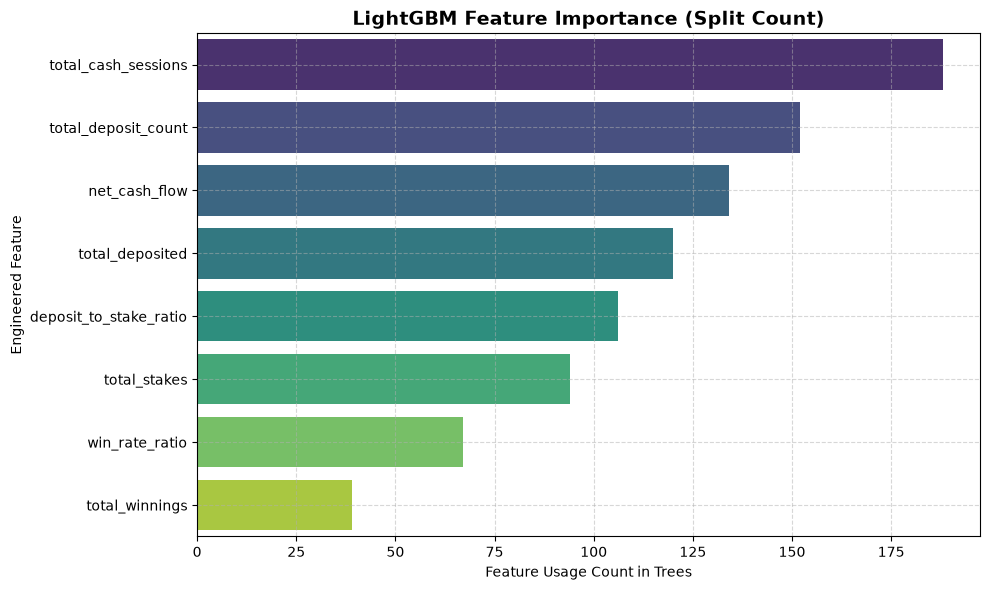

,Feature,Importance
0,total_cash_sessions,188
4,total_deposit_count,152
3,net_cash_flow,134
5,total_deposited,120
6,deposit_to_stake_ratio,106
1,total_stakes,94
7,win_rate_ratio,67
2,total_winnings,39


In [79]:
# Rank predictors using the importance measure exposed by the fitted LightGBM model.
feature_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', y='Feature', data=feature_importances,
    palette='viridis'
)
plt.title('LightGBM Feature Importance (Split Count)', fontsize=14, fontweight='bold')
plt.xlabel('Feature Usage Count in Trees')
plt.ylabel('Engineered Feature')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

display(feature_importances)


## 6. Deployment

The campaign table estimates the cost and possible retained revenue at different risk thresholds. It assumes every flagged player receives the offer, every offer has the same cost, and 25% of correctly flagged churners are retained. This is a planning scenario—not a guaranteed return. Before production use, test the assumptions in a controlled pilot, monitor model performance, and build responsible-gambling protections into campaign design.


In [80]:
# Estimate campaign economics; the assumptions below are scenario inputs, not measured effects.
import numpy as np
import pandas as pd

# Define business parameters for iGaming retention campaign
AVG_PLAYER_LTV = 150.0  # Estimated Net Revenue per retained active player ($)
RENEWAL_COST = 20.0     # Cost of targeted bonus/free-bet campaign per player ($)

# Get predictions on holdout test set
y_probs = best_model.predict_proba(X_test)[:, 1]

# Calculate campaign financials across probability thresholds
thresholds = np.arange(0.1, 1.0, 0.05)
campaign_results = []

for t in thresholds:
    # Target players flagged as churn risk above threshold t
    flagged = (y_probs >= t)
    
    tp = np.sum((flagged == 1) & (y_test == 1))  # True Churners Correctly Flagged
    fp = np.sum((flagged == 1) & (y_test == 0))  # Retained Players Falsely Flagged
    
    total_campaign_cost = (tp + fp) * RENEWAL_COST
    # Assuming campaign successfully retains 25% of targeted true churners
    retained_revenue = tp * 0.25 * AVG_PLAYER_LTV
    net_roi = retained_revenue - total_campaign_cost
    
    campaign_results.append({
        'Threshold': round(t, 2),
        'Targeted_Players': tp + fp,
        'True_Churners_Saved': int(tp * 0.25),
        'Campaign_Cost ($)': round(total_campaign_cost, 2),
        'Retained_Revenue ($)': round(retained_revenue, 2),
        'Net_ROI ($)': round(net_roi, 2)
    })

df_business = pd.DataFrame(campaign_results)
best_threshold = df_business.loc[df_business['Net_ROI ($)'].idxmax()]

print("--- OPTIMAL RETENTION CAMPAIGN THRESHOLD ---")
print(df_business.to_string(index=False))
print(f"\nOptimal Decision Threshold: {best_threshold['Threshold']}")
print(f"Projected Net ROI: ${best_threshold['Net_ROI ($)']:,}")


--- OPTIMAL RETENTION CAMPAIGN THRESHOLD ---
 Threshold  Targeted_Players  True_Churners_Saved  Campaign_Cost ($)  Retained_Revenue ($)  Net_ROI ($)
      0.10               960                  144            19200.0               21637.5       2437.5
      0.15               932                  142            18640.0               21337.5       2697.5
      0.20               894                  140            17880.0               21112.5       3232.5
      0.25               861                  139            17220.0               20850.0       3630.0
      0.30               796                  132            15920.0               19875.0       3955.0
      0.35               715                  124            14300.0               18600.0       4300.0
      0.40               616                  113            12320.0               17025.0       4705.0
      0.45               590                  110            11800.0               16537.5       4737.5
      0.50         

### Closing the loop

CRISP-DM is iterative: deployment should feed new evidence back into business understanding, data checks, and model evaluation. A responsible next step is a limited pilot with a pre-agreed success measure, a comparison group, and clear rules for excluding players who should not receive promotional contact.
